# Visualisasi Pohon Keputusan (Tanpa Modeling)

Notebook ini membuat **pohon keputusan secara manual** (rule-based) untuk dataset harga HP (`price_range`).

Yang **tidak** dipakai: `sklearn`, `DecisionTreeClassifier`, fitting/`train_test_split`.
Yang dipakai: struktur pohon dibuat tangan (nested dict), penghitungan jumlah sampel pakai pandas, lalu digambar sendiri dengan Matplotlib.

In [123]:
import pandas as pd
import matplotlib.pyplot as plt

In [124]:
# 1. Muat data
df = pd.read_csv("data_set.csv")
df = df.dropna(subset=["ram", "battery_power", "px_width", "price_range"])
print("Jumlah data:", len(df))
df[["ram", "battery_power", "px_width", "price_range"]].head()

Jumlah data: 1866


,ram,battery_power,px_width,price_range
0,2549.0,842.0,756.0,1.0
1,2631.0,1021.0,1988.0,2.0
3,2769.0,615.0,1786.0,2.0
5,1067.0,1859.0,1654.0,1.0
6,3220.0,1821.0,1018.0,3.0


## Struktur Pohon

Pohon dibuat manual dengan aturan sederhana:
1. `ram <= 1500` ?
   - Ya  -> `battery_power <= 1000` ? (Ya: Harga Rendah, Tidak: Harga Menengah)
   - Tidak -> `px_width <= 1200` ? (Ya: Harga Menengah-Tinggi, Tidak: Harga Tinggi)

In [125]:
# 2. Definisi pohon secara manual (tanpa model)
pohon = {
    "fitur": "ram <= 1500",
    "kondisi": "ram <= 1500",
    "children": {
        "Ya": {
            "fitur": "battery_power <= 1000",
            "kondisi": "battery_power <= 1000",
            "children": {
                "Ya": {     "kelas": "Harga Rendah (0)" },
                "Tidak": {  "kelas": "Harga Menengah (1)" },
            },
        },
        "Tidak": {
            "fitur": "px_width <= 1200",
            "kondisi": "px_width <= 1200",
            "children": {
                "Ya": {     "kelas": "Harga Menengah-Tinggi (2)" },
                "Tidak": {  "kelas": "Harga Tinggi (3)" },
            },
        },
    },
}


def isi_sampel(node, data):
    """Hitung jumlah sampel tiap node lewat filter pandas (bukan training)."""
    node["samples"] = len(data)
    if "children" in node:
        ya = data.query(node["kondisi"])
        tidak = data.query("not (" + node["kondisi"] + ")")
        isi_sampel(node["children"]["Ya"], ya)
        isi_sampel(node["children"]["Tidak"], tidak)


isi_sampel(pohon, df)
print("Total sampel di akar:", pohon["samples"])

Total sampel di akar: 1866


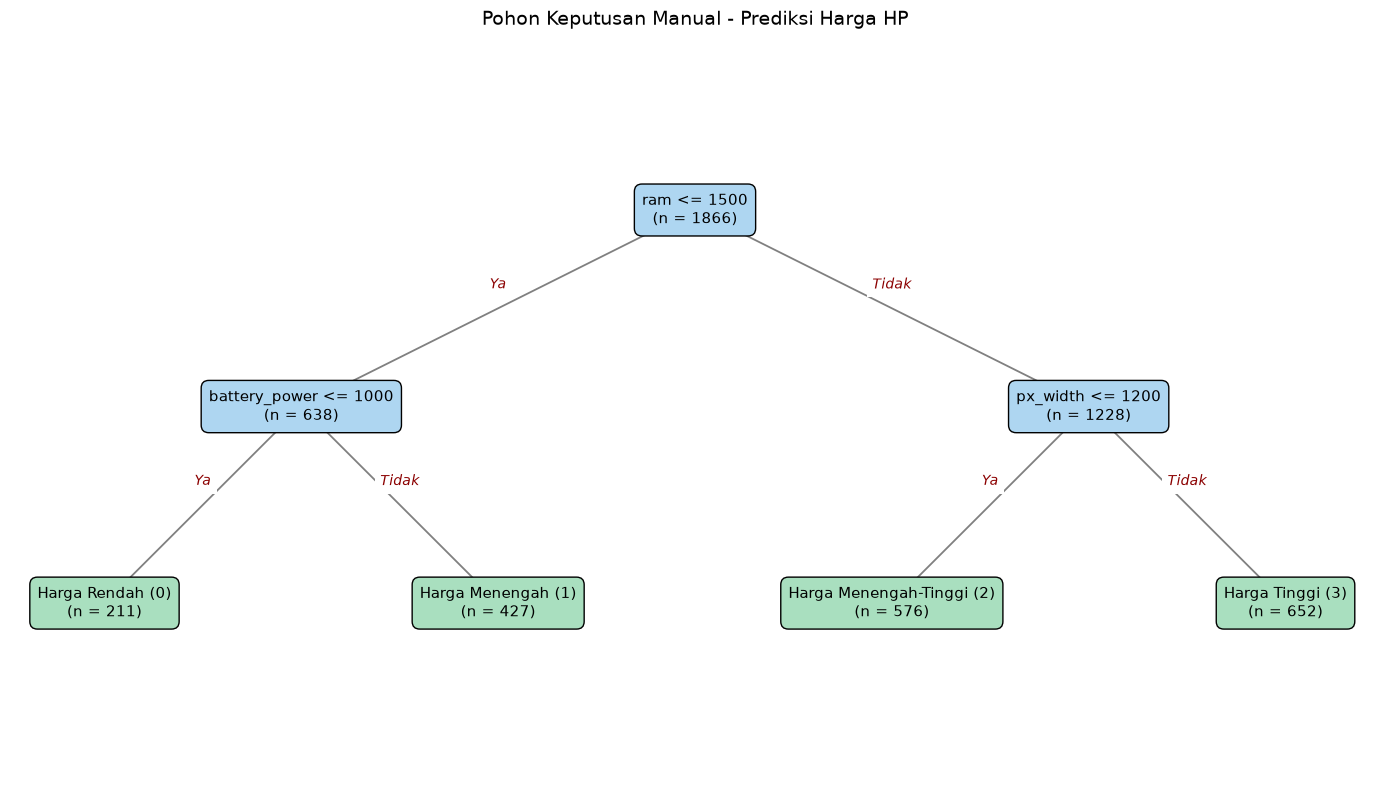

In [126]:
# 3. Fungsi menggambar pohon dengan Matplotlib
def gambar_pohon(pohon):
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.axis("off")

    pos = {}
    counter = {"x": 0}

    def layout(node, depth):
        if "children" not in node:            # daun
            pos[id(node)] = (counter["x"], -depth)
            counter["x"] += 1
            return pos[id(node)][0]
        xs = [layout(c, depth + 1) for c in node["children"].values()]
        x = sum(xs) / len(xs)
        pos[id(node)] = (x, -depth)
        return x

    layout(pohon, 0)

    def gambar_garis(node):
        x, y = pos[id(node)]
        for label, child in node.get("children", {}).items():
            cx, cy = pos[id(child)]
            ax.plot([x, cx], [y, cy], color="gray", lw=1.3, zorder=1)
            ax.text((x + cx) / 2, (y + cy) / 2 + 0.12, label, ha="center",
                    va="center", fontsize=10, color="darkred", style="italic",
                    bbox=dict(fc="white", ec="none"))
            gambar_garis(child)

    def gambar_node(node):
        x, y = pos[id(node)]
        if "children" in node:
            teks = node["fitur"] + "\n(n = " + str(node["samples"]) + ")"
            warna = "#AED6F1"
        else:
            teks = node["kelas"] + "\n(n = " + str(node["samples"]) + ")"
            warna = "#A9DFBF"
        ax.text(x, y, teks, ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="round,pad=0.5", fc=warna, ec="black"))
        for child in node.get("children", {}).values():
            gambar_node(child)

    gambar_garis(pohon)
    gambar_node(pohon)
    ax.set_ylim(-2.9, 0.9)
    ax.margins(x=0.08)
    plt.title("Pohon Keputusan Manual - Prediksi Harga HP", fontsize=14)
    plt.tight_layout()
    plt.show()


gambar_pohon(pohon)

In [127]:
# 4. Uji pohon dengan menelusuri satu baris data
def prediksi(pohon, baris):
    node = pohon
    while "children" in node:
        node = node["children"]["Ya" if baris.eval(node["kondisi"]) else "Tidak"]
    return node["kelas"]


contoh = df.iloc[0]
print("ram =", contoh["ram"], "| battery_power =", contoh["battery_power"],
      "| px_width =", contoh["px_width"])
print("Hasil prediksi pohon :", prediksi(pohon, contoh))
print("Nilai sebenarnya     :", "Harga kelas", int(contoh["price_range"]))

ram = 2549.0 | battery_power = 842.0 | px_width = 756.0


AttributeError: 'Series' object has no attribute 'eval'

## 5. Persiapan Data untuk Modeling

Supaya data dari notebook ini bisa dimasukkan ke modeling, kita siapkan:

1. Memisahkan **fitur (X)** dan **target (y = price_range)**
2. Mengisi nilai kosong pada fitur dengan nilai **median**
3. Membagi data menjadi **data latih** dan **data uji** (80% : 20%)


In [ ]:
# 5. Siapkan fitur (X) dan target (y) agar bisa dimasukkan ke modeling

# Ambil data yang labelnya (price_range) tidak kosong
data = df.dropna(subset=["price_range"]).copy()

# Fitur = semua kolom kecuali price_range, lalu isi nilai kosong dengan median
X = data.drop(columns=["price_range"])
X = X.fillna(X.median(numeric_only=True))

# Target
y = data["price_range"]

print("jumlah data :", len(data))
print("bentuk X    :", X.shape)
print("bentuk y    :", y.shape)
print("nilai kosong pada X :", int(X.isna().sum().sum()))


In [ ]:
# 6. Bagi data menjadi data latih dan data uji (80% : 20%)

data_siap = X.copy()
data_siap["price_range"] = y.values

train = data_siap.sample(frac=0.8, random_state=42)
test = data_siap.drop(train.index)

X_train = train.drop(columns=["price_range"])
y_train = train["price_range"]
X_test = test.drop(columns=["price_range"])
y_test = test["price_range"]

print("X_train :", X_train.shape, "| y_train :", y_train.shape)
print("X_test  :", X_test.shape, "| y_test  :", y_test.shape)
